In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study\fit_interband_permittivity\old_code')
from fit_interband_func_old import *
import fit_interband_func_old
importlib.reload(fit_interband_func_old)
from fit_interband_func_old  import *



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
Ag_band_info = {}

## From the mathematica code used for Stoll 2014
## Define all parameters
Ag_info = {}

Ag_info['Rosei 1974'] = {}
# Masses in electron mass unit    
Ag_info['Rosei 1974']['m_d_perp'] = 2.075
Ag_info['Rosei 1974']['m_d_par'] = 2.580
Ag_info['Rosei 1974']['m_p_perp'] = 0.320
Ag_info['Rosei 1974']['m_p_par'] = 0.172  
Ag_info['Rosei 1974']['m_s_perp'] = 5.160
Ag_info['Rosei 1974']['m_s_par'] = 0.128
#Optical gaps in eV from Rosei
Ag_info['Rosei 1974']['wf'] = 310e-3 #in eV
Ag_info['Rosei 1974']['wo'] = 3680e-3 #in eV
Ag_info['Rosei 1974']['wg'] = 3850e-3 #in eV
# Fermi Energy from Ascroft solid state physics
Ag_info['Rosei 1974']['Ef'] = 5.490 #in eV
#Drude parameters
Ag_info['Rosei 1974']['wp'] = 8.98 #in eV
Ag_info['Rosei 1974']['gamma0'] = 0.02 #in eV

#Ag_info['Rosei 1974']['Pdp'] = 10.07 #in 10^11 m_e^2  m^2/s^2
#Ag_info['Rosei 1974']['Pps'] = 4.83 #in 10^11 m_e^2  m^2/s^2



Ag_info['Stoll 2014 fitted'] = {}
# Masses in electron mass unit    
Ag_info['Stoll 2014 fitted']['m_d_perp'] = 2.075
Ag_info['Stoll 2014 fitted']['m_d_par'] = 2.580
Ag_info['Stoll 2014 fitted']['m_p_perp'] = 0.320
Ag_info['Stoll 2014 fitted']['m_p_par'] = 0.172 
Ag_info['Stoll 2014 fitted']['m_s_perp'] = 5.160
Ag_info['Stoll 2014 fitted']['m_s_par'] = 0.128
#Optical gaps in eV from Rosei
Ag_info['Stoll 2014 fitted']['wf'] = 310e-3 #in eV
Ag_info['Stoll 2014 fitted']['wo'] = 3632e-3 #in eV
Ag_info['Stoll 2014 fitted']['wg'] = 3684e-3 #in eV
# Fermi Energy from Ascroft solid state physics
Ag_info['Stoll 2014 fitted']['Ef'] = 5.490 #in eV
#Drude parameters
Ag_info['Stoll 2014 fitted']['wp'] = 8.98 #in eV
Ag_info['Stoll 2014 fitted']['gamma0'] = 0.02 #in eV

#Ag_info['Stoll 2014 fitted']['Pdp'] = np.sqrt(10.07) #in 10^11 m_e^2  m^2/s^2
#Ag_info['Stoll 2014 fitted']['Pps'] = np.sqrt(4.83)#in 10^11 m_e^2  m^2/s^2


Source = 'Rosei 1974' #As it is named in the mathematica code
Source = 'Stoll 2014 fitted'



Ag_band_info = Ag_info[Source]

Ef = Ag_info[Source]['Ef'] #in eV
Emin = Ef - 5

m_p_perp = Ag_info[Source]['m_p_perp']
m_p_par = Ag_info[Source]['m_p_par']
m_s_perp = Ag_info[Source]['m_s_perp']
m_s_par = Ag_info[Source]['m_s_par']

#gaps in eV
wf = Ag_info[Source]['wf'] 
wg = Ag_info[Source]['wg']




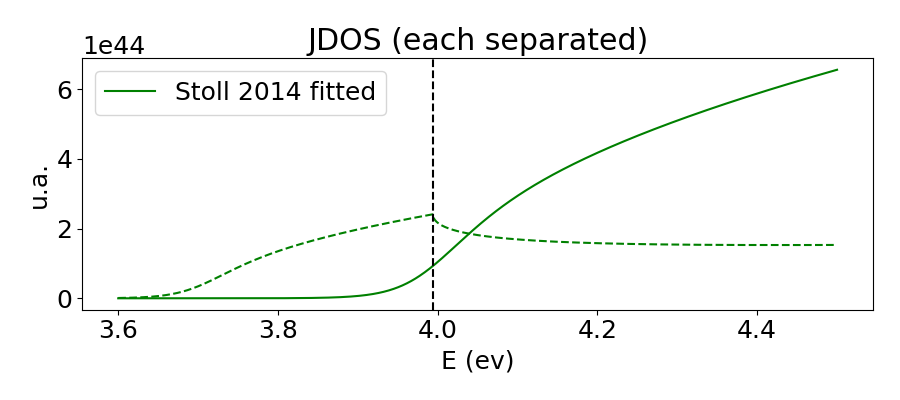

In [3]:
E_low = 3.6
E_high = 4.5
E = np.linspace(E_low, E_high, 1000) #in eV
prefactor = 8*np.pi**2 * sc.constants.hbar**2 / (sc.constants.epsilon_0*sc.constants.m_e**2)



fig, ax =plt.subplots(figsize=(9,4))


ax.plot(E, Jps_Ag_v3(E, **Ag_info['Stoll 2014 fitted']), color='green', linestyle='--')
ax.plot(E, Jdp_Ag_v3(E, **Ag_info['Stoll 2014 fitted']), color='green', label = 'Stoll 2014 fitted')
# ax.plot(E, Jps_Ag(E, **Ag_info['Rosei 1974']), color='blue', label = 'Rosei')
# ax.plot(E, Jdp_Ag(E, **Ag_info['Rosei 1974']), color='blue', linestyle='--')
ax.axvline(wf+wg, linestyle='--', color='black')


ax.set_xlabel('E (ev)')
ax.set_ylabel('u.a.')
ax.set_title('JDOS (each separated)')

ax.legend()
plt.tight_layout()

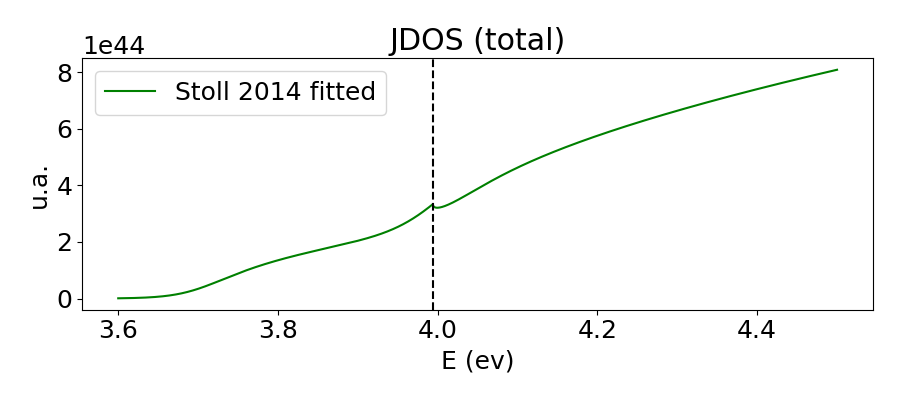

In [4]:
fig, ax =plt.subplots(figsize=(9,4))

ax.plot(E, Jps_Ag_v3(E, **Ag_info['Stoll 2014 fitted']) + Jdp_Ag_v3(E, **Ag_info['Stoll 2014 fitted']), color='green', label = 'Stoll 2014 fitted')
ax.axvline(wf+wg, linestyle='--', color='black')


ax.set_xlabel('E (ev)')
ax.set_ylabel('u.a.')
ax.set_title('JDOS (total)')

ax.legend()
plt.tight_layout()

## Fit experimental data

### Get experimental data

In [5]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'
fname = 'Ag - Jhonson.csv'
data = get_permittivity_tabulated_data(dir_root, fname)


### Remove the Drude part

In [6]:
#Gold values from Romain PhD manuscript
wp = Ag_info['Stoll 2014 fitted']['wp']  
gamma0 = Ag_info['Stoll 2014 fitted']['gamma0'] 


eps2_ib = data['eps_2'] - eps_2_drude(data['eV'], gamma=gamma0, w_p=wp)
eps2_ib_interp = sc.interpolate.interp1d(data['eV'], eps2_ib, fill_value=0, kind='quadratic')



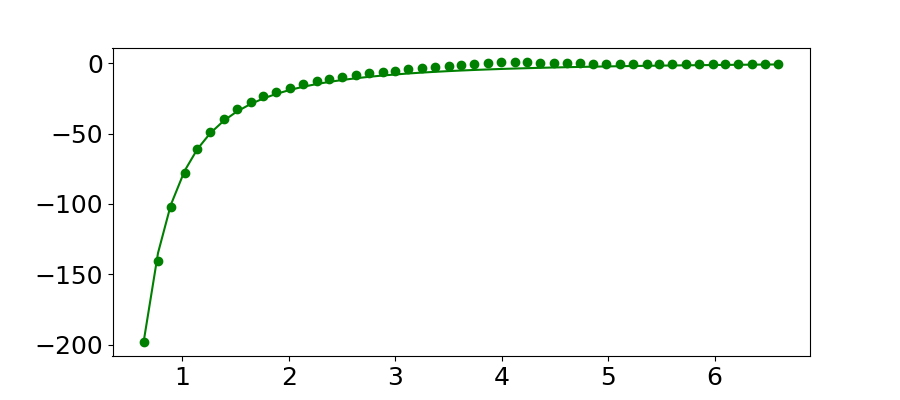

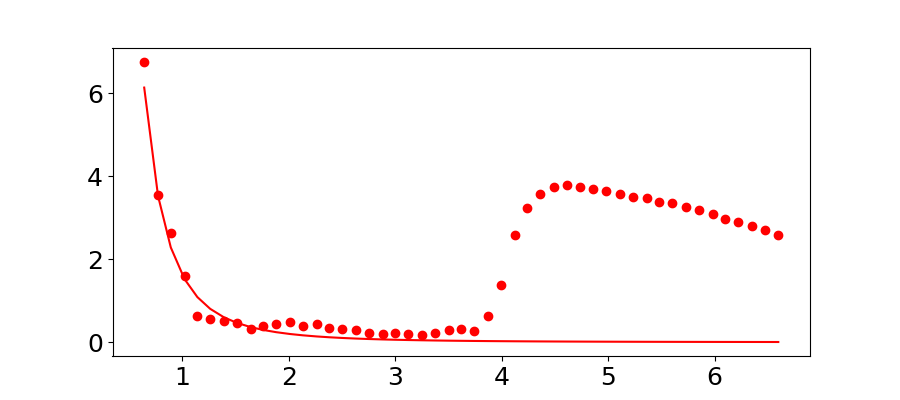

In [7]:
fig, ax =plt.subplots(figsize=(9,4))

ax.plot(data['eV'], eps_1_drude(data['eV'], gamma0, wp), color='green', label = 'Stoll 2014 Drude')
ax.scatter(data['eV'], data['eps_1'] , color='green', label = 'Jhonson and Christy')

fig, ax =plt.subplots(figsize=(9,4))

ax.plot(data['eV'], eps_2_drude(data['eV'], gamma0, wp), color='red', label = 'Stoll 2014 fitted')
ax.scatter(data['eV'], data['eps_2'] , color='red', label = 'Jhonson and Christy')

Text(0, 0.5, '$\\varepsilon_2^{ib}$')

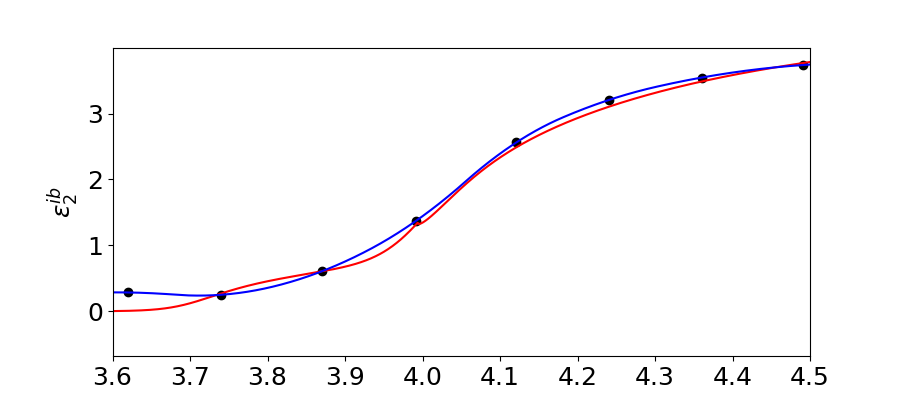

In [8]:
a = 7.8*1e-50

Pdp_ini= np.sqrt(10.07) #in 10^11 m_e^2  m^2/s^2
Pps_ini = np.sqrt(4.83)#in 10^11 m_e^2  m^2/s^2

a = 8.7*1e-51

Pdp_ini= 10.07 #in 10^11 m_e^2  m^2/s^2
Pps_ini = 4.83 #in 10^11 m_e^2  m^2/s^2

fig, ax =plt.subplots(figsize=(9,4))

ax.plot(E, eps2_from_interband(E, Pdp_ini, Pps_ini, Ag_info['Stoll 2014 fitted'])*a, color='red', )
ax.plot(E, eps2_ib_interp(E), color='blue', )
ax.scatter(data['eV'], eps2_ib , color='black', )
ax.set_xlim((E_low, E_high))

ax.set_ylabel(r'$\varepsilon_2^{ib}$')

In [9]:
free_param_list = ['wg', 'wo', 'Pdp', 'Pps']


#idx_data = np.where((data['eV']>=3.5 * data['eV']<=4.6))
Xdata = data['eV'][(data['eV']>=E_low) & (data['eV']<=E_high)]
Ydata = eps2_ib_interp(Xdata)
Ag_info['my fit'], fit_res_err, Pdp_final, Pps_final = make_Ag_interband_fit(Ag_band_info, free_param_list, Pdp_ini, Pps_ini, Xdata, Ydata)

In [10]:
for key in ['wo', 'wg'] :
    print((key, Ag_info['Stoll 2014 fitted'][key], Ag_info['my fit'][key]))

print(('Pdp', Pdp_ini, Pdp_final))

('wo', 3.632, np.float64(3.631999988942104))
('wg', 3.684, np.float64(3.6840000003740503))
('Pdp', 10.07, np.float64(3.001094240089314e-07))


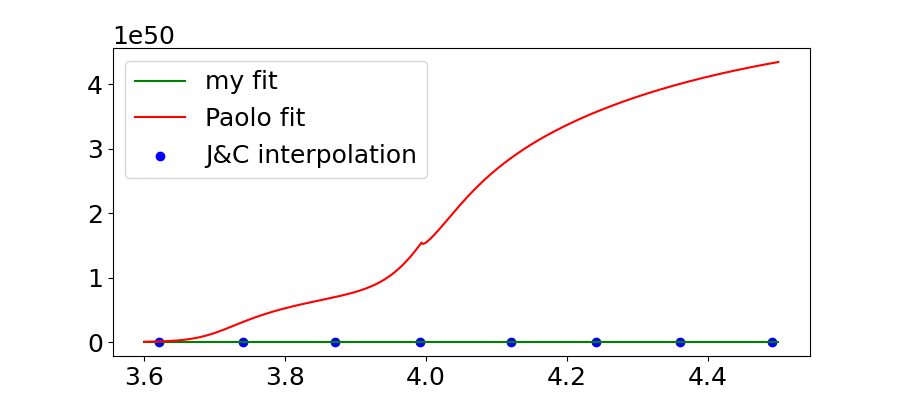

In [11]:

fig, ax =plt.subplots(figsize=(9,4))
ax.plot(E, eps2_from_interband(E, Pdp_final, Pps_final,Ag_info['my fit']), color='green', label = 'my fit')
ax.plot(E, eps2_from_interband(E, Pdp_ini, Pps_ini,Ag_info['Stoll 2014 fitted']), color='red', label='Paolo fit')
ax.scatter(Xdata, Ydata, color='blue', label = 'J&C interpolation')
ax.legend()